In [1]:
import pandas as pd
import numpy as np


In [2]:
import os
import random
import torch

def seed_everything(seed=42):
    # 1. Base Python randomness
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 2. NumPy randomness
    np.random.seed(seed)
    
    # 3. PyTorch randomness
    torch.manual_seed(seed)            # Current device (CPU or GPU)
    torch.cuda.manual_seed(seed)       # Current GPU (if applicable)
    torch.cuda.manual_seed_all(seed)   # All GPUs (multi-GPU setups)
    
    # 4. Forces PyTorch to use deterministic algorithms (Optional, can slow down performance)
    # torch.use_deterministic_algorithms(True)
    
    # 5. cuDNN backend configurations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Call this at the absolute top of your script
seed_everything(42)


In [3]:
df = pd.read_csv("archive_1/metadata.csv",index_col=0)
df.drop("n",axis = 1,inplace = True)
mask = ~df.index.duplicated(keep='first')
df = df[mask]
df.head()

,bounds,lowres_date,highres_date,area,cloud_cover,delta,lon,lat,LCCS,SMOD,IPCC Class,LCCS class,SMOD Class
Amnesty POI-10-1-1,"[105.84161265950597, 13.147748954631947, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.154895,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
Amnesty POI-10-1-2,"[105.84161265950597, 13.162040839281076, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.169187,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
Amnesty POI-10-1-3,"[105.84161265950597, 13.176332723930203, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.183479,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
Amnesty POI-10-2-1,"[105.8561973580532, 13.147748954631947, 105.87...",2019-01-06,2019-01-27,2.5,0.06,-21,105.863490,13.154895,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
Amnesty POI-10-2-2,"[105.8561973580532, 13.162040839281076, 105.87...",2019-01-06,2019-01-27,2.5,0.06,-21,105.863490,13.169187,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens


In [4]:
df.reset_index(inplace=True)

In [5]:
df['bounds'] = df['bounds'].apply(eval)

In [6]:
df

,index,bounds,lowres_date,highres_date,area,cloud_cover,delta,lon,lat,LCCS,SMOD,IPCC Class,LCCS class,SMOD Class
0,Amnesty POI-10-1-1,"[105.84161265950597, 13.147748954631947, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.154895,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
1,Amnesty POI-10-1-2,"[105.84161265950597, 13.162040839281076, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.169187,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
2,Amnesty POI-10-1-3,"[105.84161265950597, 13.176332723930203, 105.8...",2019-01-06,2019-01-27,2.5,0.06,-21,105.848905,13.183479,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
3,Amnesty POI-10-2-1,"[105.8561973580532, 13.147748954631947, 105.87...",2019-01-06,2019-01-27,2.5,0.06,-21,105.863490,13.154895,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
4,Amnesty POI-10-2-2,"[105.8561973580532, 13.162040839281076, 105.87...",2019-01-06,2019-01-27,2.5,0.06,-21,105.863490,13.169187,50,11,Forest,"Tree cover, broadleaved, evergreen, closed to ...",Rural: Very Low Dens
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3923,UNHCR-NGAs035354,"[13.778820599146073, 11.218193050313346, 13.79...",2017-11-05,2017-11-08,2.5,0.00,-3,13.786060,11.225340,190,11,Settlement,Urban areas,Rural: Very Low Dens
3924,UNHCR-MMRs035425,"[93.47666334949932, 20.0770397931716, 93.49178...",2021-04-18,2021-04-18,2.5,0.31,0,93.484222,20.084181,40,11,Agriculture,"Mosaic natural vegetation (tree, shrub, herbac...",Rural: Very Low Dens
3925,UNHCR-CMRs004018,"[14.592949197448435, 6.726291317447426, 14.607...",2019-12-05,2019-12-10,2.5,0.00,-5,14.600100,6.733440,62,11,Forest,"Tree cover, broadleaved, deciduous, open (15‐40%)",Rural: Very Low Dens
3926,UNHCR-CMRs004005,"[14.942548959144071, 6.742551322195224, 14.956...",2018-12-10,2018-10-20,2.5,0.00,51,14.949700,6.749700,190,23,Settlement,Urban areas,Urban: Dense


In [7]:
df.info(),df.shape,df.dtypes,df.columns

<class 'pandas.DataFrame'>
RangeIndex: 3928 entries, 0 to 3927
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index         3928 non-null   str    
 1   bounds        3928 non-null   object 
 2   lowres_date   3928 non-null   str    
 3   highres_date  3928 non-null   str    
 4   area          3928 non-null   float64
 5   cloud_cover   3928 non-null   float64
 6   delta         3928 non-null   int64  
 7   lon           3928 non-null   float64
 8   lat           3928 non-null   float64
 9   LCCS          3928 non-null   int64  
 10  SMOD          3928 non-null   int64  
 11  IPCC Class    3857 non-null   str    
 12  LCCS class    3928 non-null   str    
 13  SMOD Class    3928 non-null   str    
dtypes: float64(4), int64(3), object(1), str(6)
memory usage: 766.6+ KB


(None,
 (3928, 14),
 index               str
 bounds           object
 lowres_date         str
 highres_date        str
 area            float64
 cloud_cover     float64
 delta             int64
 lon             float64
 lat             float64
 LCCS              int64
 SMOD              int64
 IPCC Class          str
 LCCS class          str
 SMOD Class          str
 dtype: object,
 Index(['index', 'bounds', 'lowres_date', 'highres_date', 'area', 'cloud_cover',
        'delta', 'lon', 'lat', 'LCCS', 'SMOD', 'IPCC Class', 'LCCS class',
        'SMOD Class'],
       dtype='str'))

In [8]:
df.describe

<bound method NDFrame.describe of                    index                                             bounds  \
0     Amnesty POI-10-1-1  [105.84161265950597, 13.147748954631947, 105.8...   
1     Amnesty POI-10-1-2  [105.84161265950597, 13.162040839281076, 105.8...   
2     Amnesty POI-10-1-3  [105.84161265950597, 13.176332723930203, 105.8...   
3     Amnesty POI-10-2-1  [105.8561973580532, 13.147748954631947, 105.87...   
4     Amnesty POI-10-2-2  [105.8561973580532, 13.162040839281076, 105.87...   
...                  ...                                                ...   
3923    UNHCR-NGAs035354  [13.778820599146073, 11.218193050313346, 13.79...   
3924    UNHCR-MMRs035425  [93.47666334949932, 20.0770397931716, 93.49178...   
3925    UNHCR-CMRs004018  [14.592949197448435, 6.726291317447426, 14.607...   
3926    UNHCR-CMRs004005  [14.942548959144071, 6.742551322195224, 14.956...   
3927    UNHCR-BRAs003173  [-41.973930307054175, -12.04047654642226, -41....   

     lowres_date 

In [9]:
def bounds_to_bounding_box(
    lat_min, lon_min, lat_max, lon_max, closed=False, lonlat=False
):
    """Convert bounds to a bounding box (square).

    Parameters
    ----------
    lat_min : float
        Minimum latitude boundary.
    lon_min : float
        Minimum longitude boundary.
    lat_max : float
        Maximum latitude boundary.
    lon_max : float
        Maximum longitude boundary.
    closed : bool, optional
        Closes back to the first corner if True, by default False.
    lonlat : bool, optional
        Points in the bb are in the [longitude, latitude] order if True, in [latitude, longitude] if False. Default False.

    Returns
    -------
    list
        Four corners defining a bounding box, goes clockwise from SouthWest.
    """
    if lonlat:
        bounding_box = [
            [lon_min, lat_min],
            [lon_min, lat_max],
            [lon_max, lat_max],
            [lon_max, lat_min],
        ]
        if closed:
            bounding_box.append([lon_min, lat_min])
    else:
        bounding_box = [
            [lat_min, lon_min],
            [lat_min, lon_max],
            [lat_max, lon_max],
            [lat_max, lon_min],
        ]

        if closed:
            bounding_box.append([lat_min, lon_min])

    return bounding_box

In [10]:
from folium.plugins import MarkerCluster
import folium
from shapely.geometry.polygon import Polygon
import plotnine as p9
from plotnine import ggplot, geom_bar, aes, ggtitle, xlab, ylab, facet_wrap

#from dataset_generation.AOIGenerator import AOIGenerator
import tifffile as tiff
from PIL import Image
import numpy as np
import ipywidgets as widgets
from ipywidgets import interact
import imageio
from IPython.display import Image as IPythonImage
import os
from tqdm.notebook import tqdm
import pandas as pd

class Visualiser:
    """ Provides visualisations for all classes. """

    def __init__(self, data):
        """ Initialises the visualiser with the data to be visualised. 

        Parameters
        ----------
        data : pandas.DataFrame
            The data to be visualised.
        """
        self.data = data

    def update_data(self, data):
        """ Updates the data to be visualised.

        Parameters
        ----------
        data : pandas.DataFrame
            The data to be visualised.
        """
        self.data = data

    def visualise_points_on_map(self):
        """ Visualises points on a world map.

        Returns
        -------
        folium.Map
            The world map with the points visualised.
        """
        map = folium.Map([0, 0], zoom_start=3, tiles="CartoDB dark_matter")
        folium.TileLayer(
            "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
            attr="Tiles &copy; Esri &mdash; Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, IGN, IGP, UPR-EGP, and the GIS User Community",
        ).add_to(map)

        marker_cluster = MarkerCluster().add_to(map)
        for _, point in tqdm(self.data.iterrows(), total=len(self.data), desc="Visualising points on a map"):
            folium.Marker((point["lat"], point["lon"])).add_to(marker_cluster)
        folium.LatLngPopup().add_to(map)
        return map

    def visualise_aois_on_map(self):
        """ Visualises AOIs on a world map.

        Returns
        -------
        folium.Map
            The world map with the AOIs visualised.
        """
        map = folium.Map([0, 0], zoom_start=3, tiles="CartoDB dark_matter")
        folium.TileLayer(
            "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
            attr="Tiles &copy; Esri &mdash; Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, IGN, IGP, UPR-EGP, and the GIS User Community",
        ).add_to(map)
        aoi_style = {"fillColor": "#e74c3c", "color": "#c0392b"}
        marker_cluster = MarkerCluster().add_to(map)
        use_tooltip = pd.Series(['IPCC', 'LCCS', 'SMOD']).isin(self.data.columns).all() 
        for _, aoi in tqdm(self.data.iterrows(), total=len(self.data), desc='Visualising AOIs on map'):
            folium.Marker((aoi["lat"], aoi["lon"])).add_to(marker_cluster)
            aoi_polygon = Polygon(bounds_to_bounding_box(*aoi["bounds"]))
            aoi_geojson = folium.GeoJson(
                aoi_polygon, style_function=lambda x: aoi_style
            )
            if use_tooltip:
                aoi_tooltip = folium.Tooltip(
                    f"<strong>AOI:</strong> {aoi['name']} <br> <strong>IPCC:</strong> {aoi['IPCC']} <br> <strong>LCCS:</strong> {aoi['LCCS']} <br> <strong>SMOD:</strong> {aoi['SMOD']}"
                )
                aoi_tooltip.add_to(aoi_geojson)
            aoi_geojson.add_to(map)
        folium.LatLngPopup().add_to(map)
        return map

  

In [11]:
sample_df = df.sample(n=50, random_state=42)
visualiser = Visualiser(sample_df)
visualiser.update_data(sample_df)
visualiser.visualise_aois_on_map()

/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.


Visualising AOIs on map:   0%|          | 0/50 [00:00<?, ?it/s]

****1.Dataset Exploration> ****

In [12]:
#tof find min and max values as these are satellite iamges so can have -ve do to
# atmospheric correction
#thas why in final normlaizint we did clamping
#run complete datasetstats.pyplot

Shape: (3, 159, 158)
Dtype: float32
Min: 0.02329999953508377, Max: 0.4803999960422516, Mean: 0.0636, Median: 0.039300


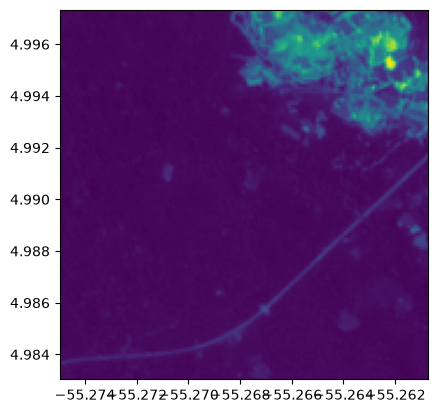

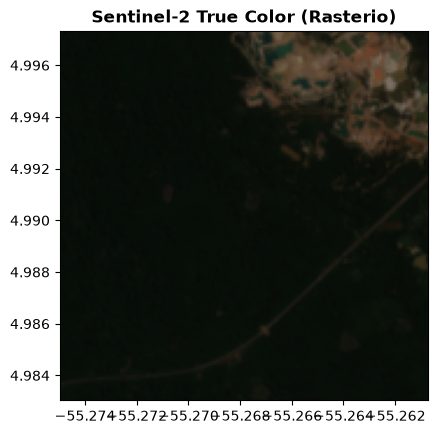

In [13]:
path = "archive_1/lr_dataset/ASMSpotter-1-1-2/L2A/ASMSpotter-1-1-2-1-L2A_data.tiff"
import rasterio
from rasterio.plot import show
import numpy as np
"""L2A data through the SentinelHub API, which already converted the Bottom-of-Atmosphere (BOA) surface reflectance directly into float32 physical decimals:

0.0 = 0% reflectance
0.15 = 15% reflectance (vegetation/soil)
0.30 = 30% reflectance (the cutoff for normal ground features!)
1.0 = 100% reflectance (clouds/snow)


so no need of normalization here
"""
# 1. Open with rasterio
with rasterio.open(path) as src:
    # Read Bands 4 (Red), 3 (Green), 2 (Blue) -> returns shape: (3, H, W)
    rgb_data = src.read([4, 3, 2])
    print("Shape:", rgb_data.shape)
    print("Dtype:", rgb_data.dtype)
    print(f"Min: {rgb_data.min()}, Max: {rgb_data.max()}, Mean: {rgb_data.mean():.4f}, Median: {np.median(rgb_data):4f}")
    show(src.read(2), transform=src.transform, cmap='viridis')
    show(rgb_data, transform=src.transform,adjust=None, title="Sentinel-2 True Color (Rasterio)")

channel_means = rgb_data.mean(axis=(1, 2))

In [14]:
#per  channel mean
channel_means[0],channel_means[1],channel_means[2]

(np.float32(0.06389222), np.float32(0.077823564), np.float32(0.04913238))

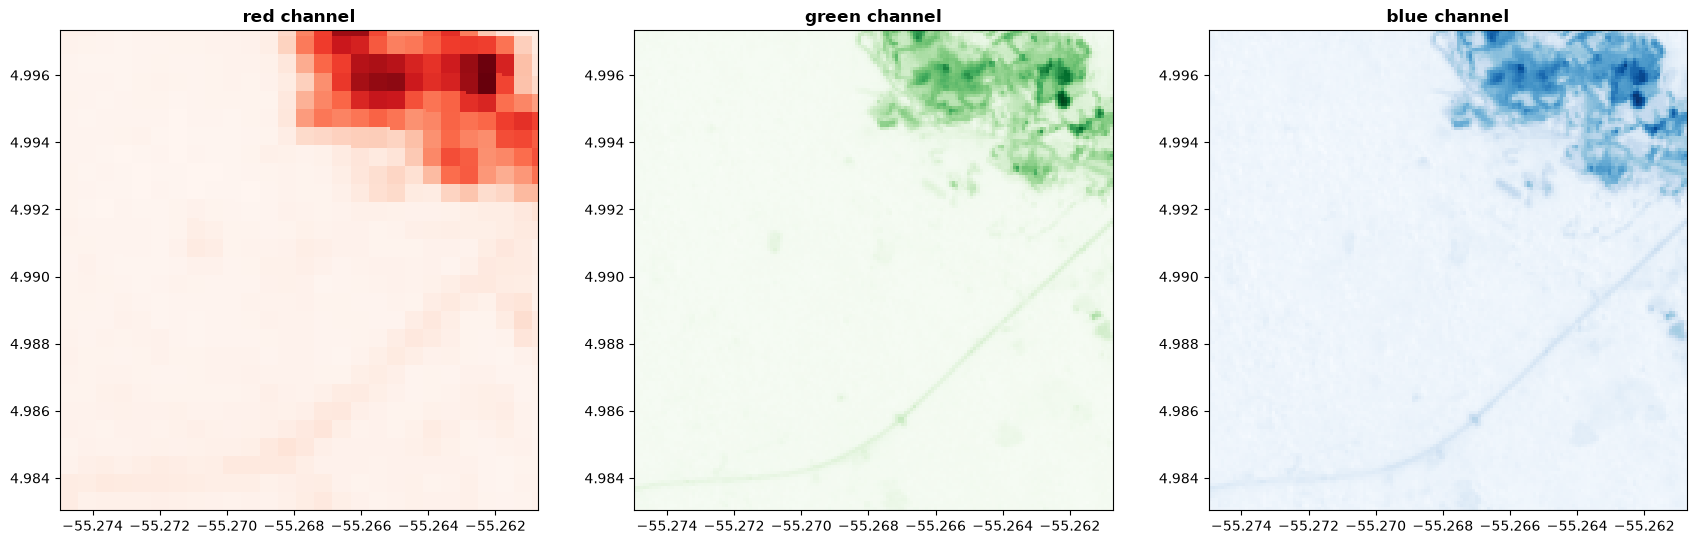

In [15]:
from matplotlib import  pyplot
with rasterio.open(path) as src:
    fig, (axr, axg, axb) = pyplot.subplots(1,3, figsize=(21,7))
    show((src, 1), ax=axr, cmap='Reds', title='red channel')
    show((src, 2), ax=axg, cmap='Greens', title='green channel')
    show((src, 3), ax=axb, cmap='Blues', title='blue channel')
    pyplot.show()

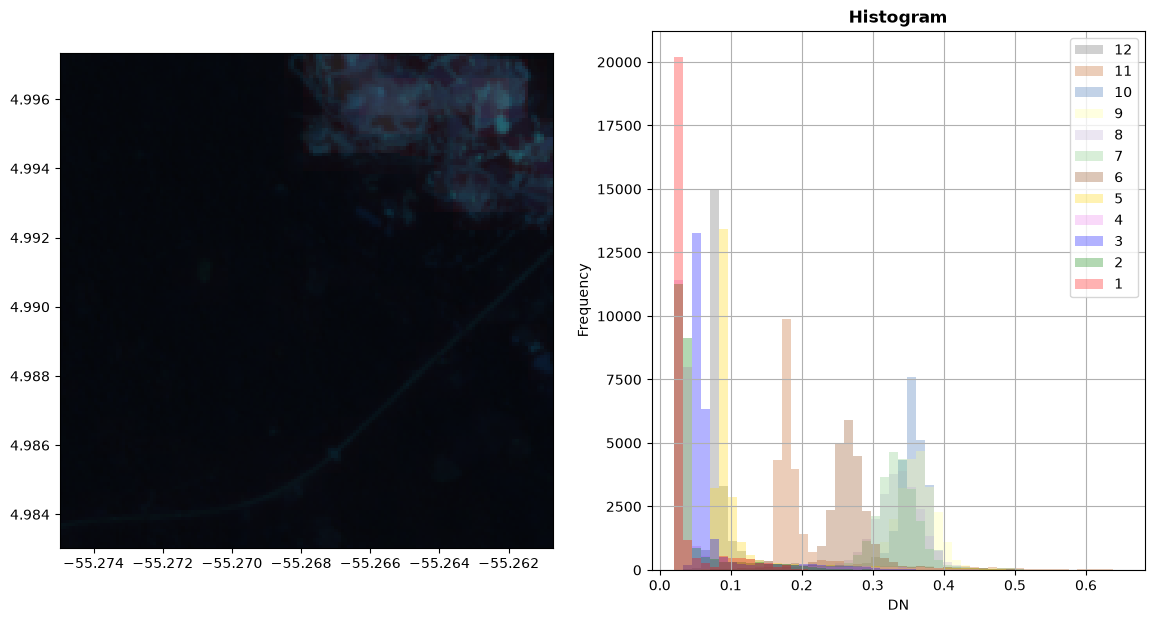

In [16]:
from rasterio.plot import show_hist
src = rasterio.open(path)
fig, (axrgb, axhist) = pyplot.subplots(1, 2, figsize=(14,7))
show(src, ax=axrgb)
show_hist(src, bins=50, histtype='stepfilled',
          lw=0.0, stacked=False, alpha=0.3, ax=axhist)
pyplot.show()

In [17]:
src

<open DatasetReader name='archive_1/lr_dataset/ASMSpotter-1-1-2/L2A/ASMSpotter-1-1-2-1-L2A_data.tiff' mode='r'>

In [18]:
from collections import Counter
from pathlib import Path

# Set the path to your directory
target_path = Path("archive_1/lr_dataset")

folder_count = 0
file_formats = Counter()

# Loop through the top-level items
for item in target_path.iterdir():
    if item.is_dir():
        folder_count += 1
    elif item.is_file():
        # Get extension in lowercase (e.g., '.txt', '.png')
        # If a file has no extension, it uses 'No Extension'
        ext = item.suffix.lower() if item.suffix else "no extension"
        file_formats[ext] += 1

# --- Print Results ---
print(f"Total Folders: {folder_count}")
print(f"Total Files:   {sum(file_formats.values())}\n")

print("File Formats Break Down:")
for ext, count in file_formats.items():
    print(f"  * {ext}: {count} file(s)")


Total Folders: 3928
Total Files:   0

File Formats Break Down:


/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..6463].


Shape: (4, 1054, 1054)
Dtype: uint16
Min: 0
Max: 8360
Mean: 542.5018
Median: 173.0000


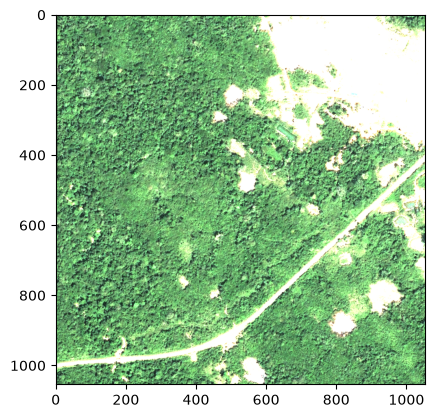

In [19]:
path = "archive_1/hr_dataset/12bit/ASMSpotter-1-1-2/ASMSpotter-1-1-2_ps.tiff"
#At this stage, src is a DatasetReader object. It only holds file properties
with rasterio.open(path) as src:
    data = src.read()#Loads pixels into RAM: This reads the actual pixel data off disk into memory.
    print("Shape:", data.shape)  
    print("Dtype:", data.dtype)  
    print(f"Min: {data.min()}")
    print(f"Max: {data.max()}")
    print(f"Mean: {data.mean():.4f}")
    print(f"Median: {np.median(data):.4f}")
    show(data, transform=src.transform)

In [20]:
import numpy as np
import rasterio

path = "archive_1/hr_dataset/12bit/ASMSpotter-1-1-2/ASMSpotter-1-1-2_ps.tiff"

with rasterio.open(path) as src:
    # 1. Storage container data type per band (e.g., 'uint8', 'uint16')
    dtypes = src.dtypes
    
    # 2. Check if the GeoTIFF explicitly tags bit depth in metadata
    explicit_bits = [src.tags(b).get("NBITS", "Not explicitly tagged") for b in range(1, src.count + 1)]
    
    # 3. Read pixel data to inspect the observed bit depth from actual values
    data = src.read()
    max_val = data.max()
    
    # Calculate bits needed to represent the maximum observed value: ceil(log2(max + 1))
    observed_bits = int(np.ceil(np.log2(max_val + 1))) if max_val > 0 else 0

    print(f"Number of bands: {src.count}")
    print(f"Data type per band: {dtypes}")
    print(f"Metadata NBITS tag: {explicit_bits}")
    print(f"Max pixel value: {max_val}")
    print(f"Effective bit depth (from values): ~{observed_bits}-bit")

Number of bands: 4
Data type per band: ('uint16', 'uint16', 'uint16', 'uint16')
Metadata NBITS tag: ['Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged']
Max pixel value: 8360
Effective bit depth (from values): ~14-bit


/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.


In [21]:
import numpy as np
import rasterio

path = "archive_1/lr_dataset/ASMSpotter-1-1-2/L2A/ASMSpotter-1-1-2-1-L2A_data.tiff"

with rasterio.open(path) as src:
    # 1. Storage container data type per band (e.g., 'uint8', 'uint16')
    dtypes = src.dtypes
    
    # 2. Check if the GeoTIFF explicitly tags bit depth in metadata
    explicit_bits = [src.tags(b).get("NBITS", "Not explicitly tagged") for b in range(1, src.count + 1)]
    
    # 3. Read pixel data to inspect the observed bit depth from actual values
    data = src.read()
    max_val = data.max()
    
    # Calculate bits needed to represent the maximum observed value: ceil(log2(max + 1))
    observed_bits = int(np.ceil(np.log2(max_val + 1))) if max_val > 0 else 0

    print(f"Number of bands: {src.count}\n")
    print(f"Data type per band: {dtypes}\n")
    print(f"Metadata NBITS tag: {explicit_bits}\n")
    print(f"Max pixel value: {max_val}\n")
    print(f"Effective bit depth (from values): ~{observed_bits}-bit")

Number of bands: 12

Data type per band: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')

Metadata NBITS tag: ['Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged', 'Not explicitly tagged']

Max pixel value: 0.6510999798774719

Effective bit depth (from values): ~1-bit


In [22]:
#show_aoi = interact_manual.options(manual_name="Show AOI")

In [23]:
dataset_root = 'archive_1/'
hr_dataset_folder = 'hr_dataset/'
lr_dataset_folder = 'lr_dataset/'
import os
root=os.path.join(dataset_root, lr_dataset_folder, "*", "L2A", "")
print(root)

archive_1/lr_dataset/*/L2A/


In [24]:
import os
import glob
# 1. Build the path string with the wildcard
root_pattern = os.path.join(dataset_root, lr_dataset_folder, "*", "L2A", "")
root_pattern2=os.path.join(dataset_root, hr_dataset_folder,"12bit", "*")
# 2. Search for all paths that match the pattern
actual_paths = glob.glob(root_pattern)
actual_paths2 = glob.glob(root_pattern2)

print(f"Found {len(actual_paths)} matching directories.")
print(f"Found {len(actual_paths2)} matching directories.")

Found 3928 matching directories.
Found 3929 matching directories.


In [25]:
from glob import glob
print(glob("archive_1/lr_dataset/*/L2A/")[:5])

['archive_1/lr_dataset/ASMSpotter-18-2-1/L2A/', 'archive_1/lr_dataset/ASMSpotter-13-2-1/L2A/', 'archive_1/lr_dataset/ASMSpotter-11-1-1/L2A/', 'archive_1/lr_dataset/UNHCR-NGAs036315/L2A/', 'archive_1/lr_dataset/Amnesty POI-19-3-1/L2A/']


In [26]:
import os
from glob import glob
from multiprocessing import Manager
import natsort
import numpy as np
import rasterio
import torch
from torch.utils.data import Dataset
from torchvision.transforms import Compose, Resize, InterpolationMode, Normalize, Lambda

#i din't include compyut_median_std() as i pasted precomputed values and also panchromatic conversoin tooo as we are working 
# on pre computed dataset
class SatelliteDataset(Dataset):
    """PyTorch Dataset class used to load satellite imagery. """

    def __init__(
        self,
        root,
        number_of_revisits=8,
        subdir="",
        file_postfix=None,
        transform=None,
        bands_to_read=None,
        file_reader=None,
        use_cache=True,
        multiprocessing_manager=None,
    ):
        """PyTorch Dataset class used to load satellite imagery.

        Parameters
        ----------
        root : str
            Path to a directory that contains either one subdirectory per AOI or one file per AOI revisit.
            Every subdirectory would contain the revisits for that AOI.

        subdir : str, optional
            Subdirectory within the root where revisits are, by default '' (no subdirectory).

        file_postfix : str, optional
            The postfix in which the revisit files end, by default 'tif*'.
            Allows wildcards.

        number_of_revisits : int, optional
            The number of revisits to get for each AOI, by default None (all revisits).

        transform : torchvision.transform, optional
            A transform that is applied to each revisit, by default Compose([]) (no transform).

        bands_to_read : list, optional
            A list of band IDs to read, by default None.
            By GDAL convention, band IDs are 1-indexed.

        file_reader : callable, optional
            A callable function used to read the files, by default SatelliteDataset.read_tiff_with_rasterio.

        use_cache : bool, optional
            Cache fetched items to memory, by default True.
            Can require a lot of RAM, but greatly speeds up training.

        multiprocessing_manager : multiprocessing.Manager, optional
            Used to prevent CPU memory leaking when multiple DataLoader workers access the cache, by default None.
            multiprocessing.Manager data structures are used to prevent copy-on-write behaviour due to refcounts in Python.
            See: https://github.com/pytorch/pytorch/issues/13246.
        """

        self.check_root_is_not_empty(root)
        self.root = root
        self.subdir = subdir
        self.file_postfix = file_postfix if file_postfix is not None else "tif*"
        self.file_reader = file_reader or self.read_tiff_with_rasterio
        self.transform = transform or Compose([])
        self.bands_to_read = list(bands_to_read) if bands_to_read is not None else None
        self.number_of_revisits = number_of_revisits
        self.multiprocessing_manager = multiprocessing_manager
        self.paths = self.load_and_sort_aoi_paths(root)
        self.use_cache = use_cache
        
        if self.use_cache:
            if self.multiprocessing_manager is None:
                self.manager = Manager()
                self.cache = self.manager.dict()
            else:
                self.cache = self.multiprocessing_manager.dict()
        else:
            self.cache = None

    @staticmethod
    def check_root_is_not_empty(root):
        """Checks that the root is not empty.

        Parameters
        ----------
        root : str
            Path to a directory that contains either one subdirectory per AOI or one file per AOI revisit.
        """
        assert len(glob(root)) > 0, f"No files from {root}."

    def __len__(self):
        """Returns the number of AOIs in the dataset.

        Returns
        -------
        int
            The number of AOIs in the dataset.
        """
        return len(self.paths)

    def __getitem__(self, item: int):
        """Returns a satellite image for a given AOI index from the dataset.
        If the image was previously fetched, it is returned from the cache.
        Otherwise, it is fetched from the disk and transformed.

        Parameters
        ----------
        item : int
            The index of the AOI in the dataset.

        Returns
        -------
        Tensor
            The satellite image as a tensor.
        """
        if not self.use_cache or item not in self.cache:
            path = self.paths[item]
            if os.path.isdir(path):
                # The path is a folder
                return self.load_revisits_from_folder(path, item)
            else:
                # The path is a single file
                x = self.file_reader(path, self.bands_to_read)
                x = self.transform(x)
                if self.use_cache:
                    self.cache[item] = x
                return x
        else:
            # The item is cached, return from cache
            return self.cache[item]

    @staticmethod
    def read_tiff_with_rasterio(path, bands_to_read=None):
        """Reads a TIFF file using rasterio.

        Parameters
        ----------
        path : str
            The path to the TIFF file.
        bands_to_read : list, optional
            A list of band IDs to read, by default None.

        Returns
        -------
        Tensor
            The image as a tensor.
        """
        data = rasterio.open(path).read(indexes=bands_to_read, window=None)
        return torch.as_tensor(data.astype(np.float32))

    def load_and_sort_aoi_paths(self, root):
        """Loads the AOI paths from the root and sorts them.

        Parameters
        ----------
        root : str
            The path to the root directory.

        Returns
        -------
        multiprocessing.Manager.list
            A list of AOI paths, naturally sorted.
        """
        if self.multiprocessing_manager is not None:
            return self.multiprocessing_manager.list(natsort.natsorted(glob(root)))
        else:
            return natsort.natsorted(glob(root))

    def load_revisits_from_folder(self, path, item):
        """Loads the revisits/satellite images for a given AOI from a folder.

        Parameters
        ----------
        path : str
            The path to the AOI folder.
        item : int
            The index of the AOI in the dataset.

        Returns
        -------
        Tensor
            The revisits as a tensor.
        """
        # The folder contains revisits for a single AOI, read them into an AOI-specific dataset
        search_path = os.path.join(path, self.subdir, f"*{self.file_postfix}")
        revisit_files = natsort.natsorted(glob(search_path))

        if len(revisit_files) == 0:
            return None

        # Determine the number of revisits to return
        if self.number_of_revisits:
            if len(revisit_files) < self.number_of_revisits:
                revisit_files = (revisit_files * ((self.number_of_revisits // len(revisit_files)) + 1))[:self.number_of_revisits]
            else:
                revisit_files = revisit_files[:self.number_of_revisits]

        # Stack along revisit/time dimension -> (revisits, bands, height, width)
        revisits = [self.file_reader(f, self.bands_to_read) for f in revisit_files]
        x = torch.stack(revisits, dim=0)

        x = self.transform(x)
        self.cache_revisits(item, x)
        return x

    def cache_revisits(self, item, x):
        """Caches the AOI revisits within the multiprocessing.Manager dictionary.

        Parameters
        ----------
        item : int
            The index of the AOI in the dataset.
        x : Tensor
            The revisits as a tensor.
        """
        if self.use_cache:
            self.cache[item] = x


In [27]:

class DictDataset(Dataset):
    """ PyTorch Dataset class used to wrap a dictionary of datasets.
    The item index passed to the get method refers to images from a single AOI, or patch (when cropping is applied).
    The get method returns a dictionary of the items at the item index for each dataset."""

    def __init__(self, **dictionary_of_datasets):
        """

        Parameters
        ----------
        dictionary_of_datasets : dict
            The dictionary of torch datasets to wrap.

                                                                    self.datasets = {
                                                                "lr": <SatelliteDataset instance for Sentinel-2>,
                                                                "hr": <SatelliteDataset instance for SPOT HR>
                                                            }

        """
        # self.datasets = {
        #     dataset_name: dataset
        #     for dataset_name, dataset in dictionary_of_datasets.items()
        #     if isinstance(dataset, Dataset)
        # }
        self.datasets = {}  # 1. Start with an empty dictionary
    
        for dataset_name, dataset in dictionary_of_datasets.items():  # 2. Loop through every pair
            if isinstance(dataset, Dataset):  # 3. Check if it's a PyTorch Dataset
                self.datasets[dataset_name] = dataset  # 4. If yes, save it in the dictionary


    def __getitem__(self, item):
        """Get an item from the datasets.

        Parameters
        ----------
        item : int
            The index of the item to get from each dataset.

        Returns
        -------
        dict
            The items from each dataset (dataset_name:item).
        """
        return {name: dataset[item] for name, dataset in self.datasets.items()}

    def __len__(self):
        """Returns the length of the smallest dataset in the dictionary of wrapped datasets.

        Returns
        -------
        int
            The length of the smallest dataset in the dictionary of wrapped datasets.
        """
        return min(len(dictionary) for dictionary in self.datasets.values())


In [28]:
import os
import torch
from glob import glob

# ------------------------------------------------------ #
#                  Sentinel2   - S2
#                  Level 2A   - L2A
#                  Level 1C   - L1C
# ------------------------------------------------------ #


# Source: https://custom-scripts.sentinel-hub.com/custom-scripts/sentinel-2/composites/
# NOTE: these are 1-indexed because GDAL is 1-indexed.
S2_ALL_12BANDS = {
    "true_color": [4, 3, 2],
    "false_color": [8, 4, 3],
    "swir": [12, 8, 4],
    "agriculture": [11, 8, 2],
    "geology": [12, 11, 2],
    "bathimetric": [4, 3, 1],
    "true_color_zero_index": [3, 2, 1],
}

S2_ALL_BANDS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

# ------------------------------------------------------ #
#                  SpaceNet7   - SN7
#                  PlanetScope - PS
# ------------------------------------------------------ #

PS_BANDS = [1, 2, 3]

METADATA_PATH = 'dataset/metadata.csv'
ROOT_SN7_DATA = os.path.join("data", "SN7")
ROOT_SN7_DATA_TRAIN = os.path.join(ROOT_SN7_DATA, "train")
SCENES_SN7 = glob(os.path.join(ROOT_SN7_DATA_TRAIN, "L15*"))

SN7_SUBDIRECTORIES = {"lr": "S2", "lrc": "S2_masks", "hr": "images"}
SN7_BANDS_TO_READ = {"lr": S2_ALL_12BANDS["true_color"], "lrc": None, "hr": PS_BANDS}


# Precomputed on training data by running: src/datasets.py
S2_SN7_MEAN = torch.Tensor(
    [
        0.0769,
        0.0906,
        0.1162,
        0.1318,
        0.1619,
        0.2275,
        0.2500,
        0.2588,
        0.2667,
        0.2684,
        0.2461,
        0.1874,
    ]
).to(torch.float64)

S2_SN7_STD = torch.Tensor(
    [
        0.1708,
        0.1672,
        0.1614,
        0.1677,
        0.1698,
        0.1513,
        0.1490,
        0.1515,
        0.1461,
        0.2365,
        0.1472,
        0.1418,
    ]
).to(torch.float64)

PS_MEAN = torch.Tensor([105.0, 92.0, 66.0]).to(torch.float64)  # RGB
PS_STD = torch.Tensor([58.2366, 47.1755, 44.9830]).to(torch.float64)
SN7_MAX_EXPECTED_HR_VALUE = 255


# ------------------------------------------------------ #
#   Satellite pour l'Observation de la Terre - SPOT 7
#   Julien, Ivan, Freddie (working name)     - JIF
# ------------------------------------------------------ #

SPOT_BANDS = [0, 1, 2, 3]
SPOT_RGB_BANDS = [1, 2, 3]
SPOT_MAX_EXPECTED_VALUE_8_BIT = 255
SPOT_MAX_EXPECTED_VALUE_12_BIT = 10000

ROOT_JIF_DATA = os.path.join("data", "JIF")
ROOT_JIF_DATA_TRAIN = os.path.join(ROOT_JIF_DATA, "train")

# Precomputed on training data by running: src/datasets.py
JIF_S2_MEAN = torch.Tensor(
    [
        0.0008,
        0.0117,
        0.0211,
        0.0198,
        0.0671,
        0.1274,
        0.1449,
        0.1841,
        0.1738,
        0.1803,
        0.0566,
        -0.0559,
    ]
).to(torch.float64)

JIF_S2_STD = torch.Tensor(
    [
        0.0892,
        0.0976,
        0.1001,
        0.1169,
        0.1154,
        0.1066,
        0.1097,
        0.1151,
        0.1122,
        0.1176,
        0.1298,
        0.1176,
    ]
).to(torch.float64)

URBAN_SPOT_MEAN = torch.Tensor([0.0025, 0.0022, 0.0017]).to(torch.float64)
URBAN_SPOT_STD = torch.Tensor([0.0021, 0.0018, 0.0017]).to(torch.float64)


In [29]:
def make_transforms_JIF(
    input_size=(160, 160),
    output_size=(1054, 1054),
    interpolation=InterpolationMode.BICUBIC,
    normalize_lr=True,
    scene_classification_to_color=False,
    radiometry_depth=12,
    lr_bands_to_use="all",
    **kws,
):
    """ Make the transforms for the JIF dataset.
    The transforms normalize and resize the images to the appropriate sizes.
    """
    if radiometry_depth == 8:
        maximum_expected_hr_value = SPOT_MAX_EXPECTED_VALUE_8_BIT
    else:
        maximum_expected_hr_value = SPOT_MAX_EXPECTED_VALUE_12_BIT

    transforms = {}
    if lr_bands_to_use == "true_color":
        lr_bands_to_use = np.array(S2_ALL_12BANDS["true_color"]) - 1
    else:
        lr_bands_to_use = np.array(S2_ALL_BANDS) - 1

    if normalize_lr:
        normalize = Normalize(
            mean=JIF_S2_MEAN[lr_bands_to_use].float(), std=JIF_S2_STD[lr_bands_to_use].float()
        )
    else:
        normalize = Compose([])

    # Safe float32 tensor converter (works seamlessly on both torch.Tensor and np.ndarray)
    to_float_tensor = lambda img: img.float() if isinstance(img, torch.Tensor) else torch.as_tensor(img, dtype=torch.float32)

    transforms["lr"] = Compose(
        [
            Lambda(to_float_tensor),
            normalize,
            Resize(size=input_size, interpolation=interpolation, antialias=True),
        ]
    )

    transforms["lrc"] = Compose(
        [
            Lambda(to_float_tensor),
            Resize(size=input_size, interpolation=InterpolationMode.NEAREST),
            SceneClassificationToColorTransform
            if scene_classification_to_color
            else Compose([]),
        ]
    )

    transforms["hr"] = Compose(
        [
            Lambda(
                lambda hr_revisit: (
                    hr_revisit.float()
                    if isinstance(hr_revisit, torch.Tensor)
                    else torch.as_tensor(hr_revisit, dtype=torch.float32)
                )
                / maximum_expected_hr_value
            ),
            Resize(size=output_size, interpolation=interpolation, antialias=True),
            Lambda(lambda high_res_revisit: high_res_revisit.clamp(min=0, max=1)),
        ]
    )

    transforms["hr_pan"] = Compose(
        [
            Lambda(
                lambda hr_panchromatic: (
                    hr_panchromatic.float()
                    if isinstance(hr_panchromatic, torch.Tensor)
                    else torch.as_tensor(hr_panchromatic, dtype=torch.float32)
                )
                / maximum_expected_hr_value
            ),
            Resize(size=output_size, interpolation=interpolation, antialias=True),
            Lambda(
                lambda high_res_panchromatic: high_res_panchromatic.clamp(min=0, max=1)
            ),
        ]
    )
    return transforms


for sentinal2
Why do this for inputs? Deep neural network layers (convolutions, activations) learn fastest and avoid gradient vanishing/explosion when input features are centered around zero

for hr one
appled maxscaling to make 0 to 1 and clamping



In [30]:
import os

from ipywidgets import interact_manual, Layout
import ipywidgets as widgets
from glob import glob
from torch.utils.data import DataLoader
from torchvision.utils import make_grid


from multiprocessing import Manager
transforms = make_transforms_JIF(lr_bands_to_use='true_color', radiometry_depth=12)
multiprocessing_manager = Manager()

dataset_root = 'archive_1/'
hr_dataset_folder = 'hr_dataset/12bit/'
lr_dataset_folder = 'lr_dataset/'

In [31]:
lr = SatelliteDataset(
    root=os.path.join(dataset_root, lr_dataset_folder, "*", "L2A", ""),
    file_postfix="-L2A_data.tiff",
    transform=transforms["lr"],
    number_of_revisits=8,
    bands_to_read=S2_ALL_12BANDS["true_color"],
    multiprocessing_manager=multiprocessing_manager
)

lrc = SatelliteDataset(
    root=os.path.join(dataset_root, lr_dataset_folder, "*", "L2A", ""),
    file_postfix="-CLM.tiff",
    transform=transforms["lrc"],
    number_of_revisits=8,
    multiprocessing_manager=multiprocessing_manager
)

hr_panchromatic = SatelliteDataset(
    root=os.path.join(dataset_root, hr_dataset_folder, "*"),
    file_postfix="_pan.tiff",
    transform=transforms["hr_pan"],
    number_of_revisits=1,
    multiprocessing_manager=multiprocessing_manager
)

hr_rgb = SatelliteDataset(
    root=os.path.join(dataset_root, hr_dataset_folder, "*"),
    file_postfix="_rgbn.tiff",
    transform=transforms["hr"],
    bands_to_read=SPOT_RGB_BANDS,
    number_of_revisits=1,
    multiprocessing_manager=multiprocessing_manager
)

hr_pansharpened = SatelliteDataset(
    root=os.path.join(dataset_root, hr_dataset_folder, "*"),
    file_postfix="_ps.tiff",
    transform=transforms["hr"],
    bands_to_read=SPOT_RGB_BANDS,
    number_of_revisits=1,
    multiprocessing_manager=multiprocessing_manager
)

dataset = DictDataset(
    **{
        "lr": lr,
        "lrc": lrc,
        "hr": hr_rgb,
        "hr_pan": hr_panchromatic,
        "hr_pansharpened": hr_pansharpened,
    }
)

print(f"Loaded dataset with {len(dataset)} images.")

Loaded dataset with 3928 images.


/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.


torch.Size([8, 3, 160, 160])
(8, 3, 160, 160)
(3, 160, 160)


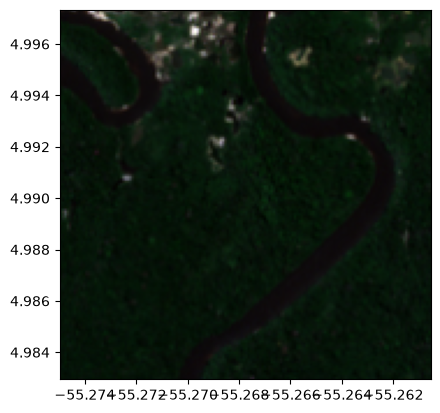

<Axes: >

In [32]:
import random
random_number = random.randint(1, 20)#18 is good
t = dataset[18]
print(t["lr"].shape)
numpy_array = t["lr"].numpy()
print(numpy_array.shape)
numpy_array[0]#first image
print(numpy_array[0].shape)
show(numpy_array[0],transform=src.transform,adjust="linear")

In [33]:
numpy_array[0]

array([[[0.49891075, 0.4250652 , 0.3039518 , ..., 0.14967985,
         0.14974922, 0.15820716],
        [0.23723717, 0.22129714, 0.21556105, ..., 0.15900557,
         0.16162622, 0.18158044],
        [0.21861526, 0.21426068, 0.2041994 , ..., 0.16501936,
         0.17905863, 0.23059629],
        ...,
        [0.11262254, 0.10562677, 0.08264705, ..., 0.13015305,
         0.1664703 , 0.17269437],
        [0.13531917, 0.1063865 , 0.10394744, ..., 0.11289141,
         0.138433  , 0.12187279],
        [0.12147913, 0.10528568, 0.11543733, ..., 0.12185801,
         0.14291695, 0.1282883 ]],

       [[0.45024052, 0.39411378, 0.33341262, ..., 0.43215615,
         0.42868176, 0.45451462],
        [0.28576487, 0.268371  , 0.25406304, ..., 0.4534141 ,
         0.4680821 , 0.4895115 ],
        [0.24864645, 0.26049364, 0.24052085, ..., 0.4666294 ,
         0.51403356, 0.56721324],
        ...,
        [0.3723081 , 0.31301993, 0.26985088, ..., 0.34713274,
         0.39588568, 0.39433387],
        [0.3

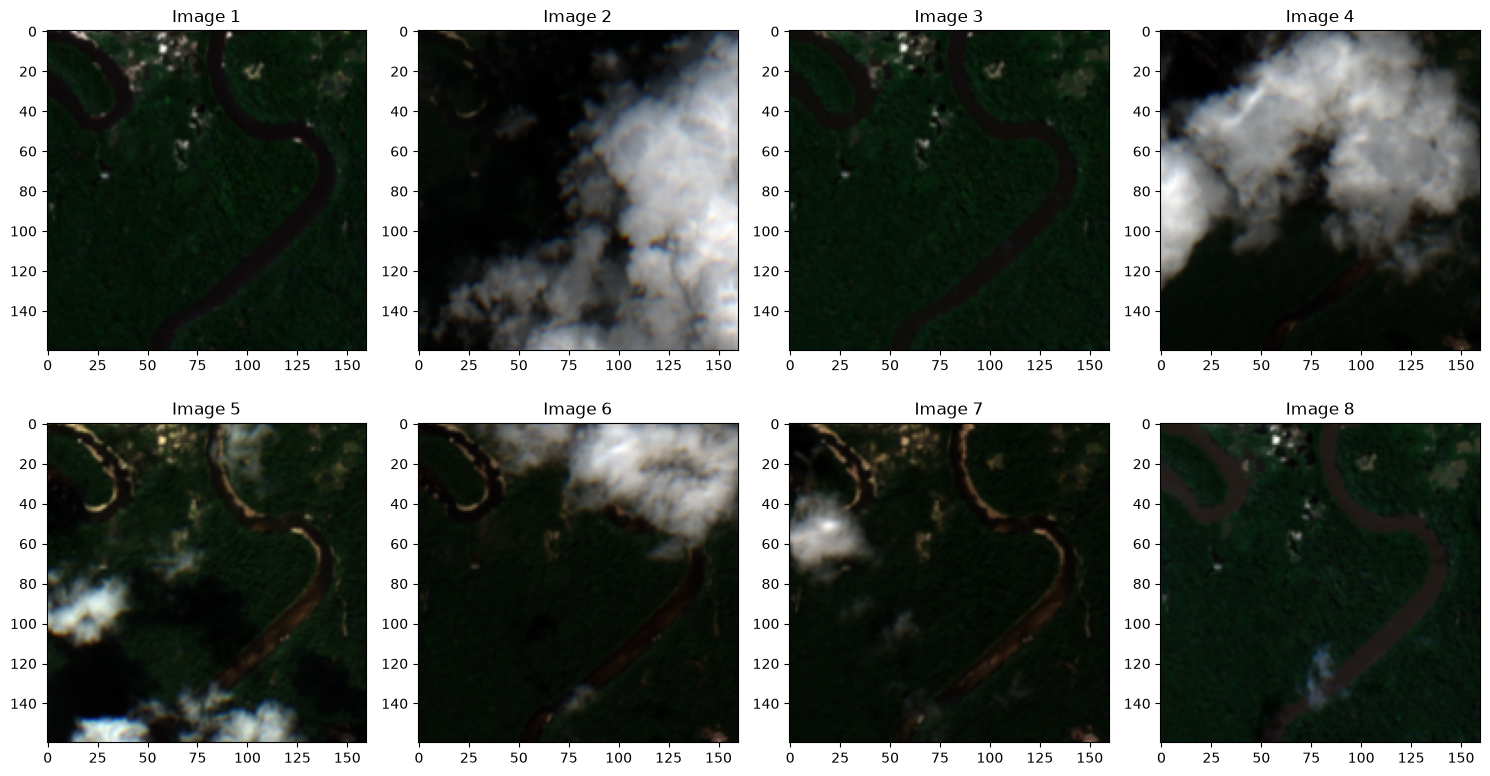

In [34]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(15, 8))
axes_flat = axes.flatten()
for i, single_image in enumerate(numpy_array):
    show(single_image, ax=axes_flat[i],adjust= "linear")
    axes_flat[i].set_title(f"Image {i+1}")
plt.tight_layout()
plt.show()


(338, 670, 3)


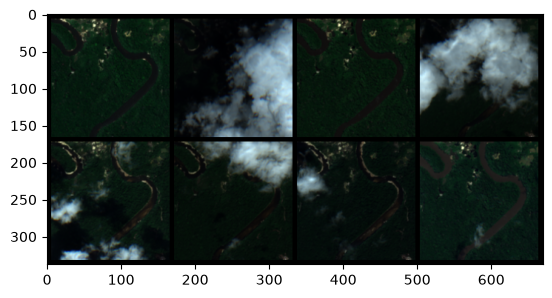

In [35]:
lr_grid = make_grid(
    torch.tensor(numpy_array[:, :3]), nrow=4, normalize=True, scale_each=True, padding=6
)

# 2. Move to CPU, permute channels to (H, W, C), and convert to NumPy
grid_np = lr_grid.permute(1, 2, 0).cpu().numpy()

# 3. Plot the grid
print(grid_np.shape)
plt.imshow(grid_np)


(3, 338, 670)


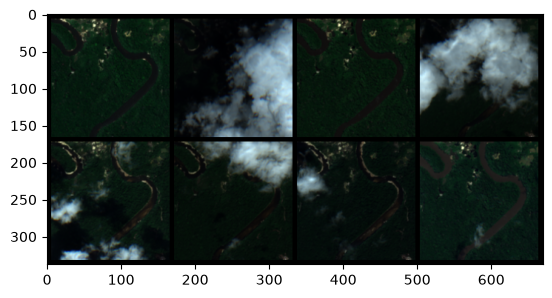

<Axes: >

In [36]:
lr_grid = make_grid(
    torch.tensor(numpy_array[:, :3]), nrow=4, normalize=True, scale_each=True, padding=6
)

grid_np = lr_grid.cpu().numpy()
print(grid_np.shape)
show(grid_np)

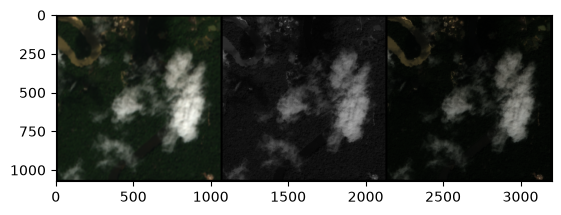

<Axes: >

In [37]:
#as make grid accept tensor (Tensor or list) – 4D mini-batch Tensor of shape (B x C x H x W) or a list of images all of the same size
hr, hr_pan, ps = t['hr'], t['hr_pan'], t['hr_pansharpened']
rgb = hr[0]
pan = hr_pan[0]
pan_3ch = pan.repeat(3, 1, 1) if pan.shape[0] == 1 else pan[:3]
ps_img = ps[0]
hr_grid = make_grid([rgb[:3], pan_3ch[:3], ps_img[:3]], nrow=3, normalize=True, scale_each=True, padding=10)
img = hr_grid.cpu().numpy()
show(img)

=== AOI Index: 18 | LR Shape: (8, 3, 160, 160) | HR Shape: (1, 3, 1054, 1054) ===


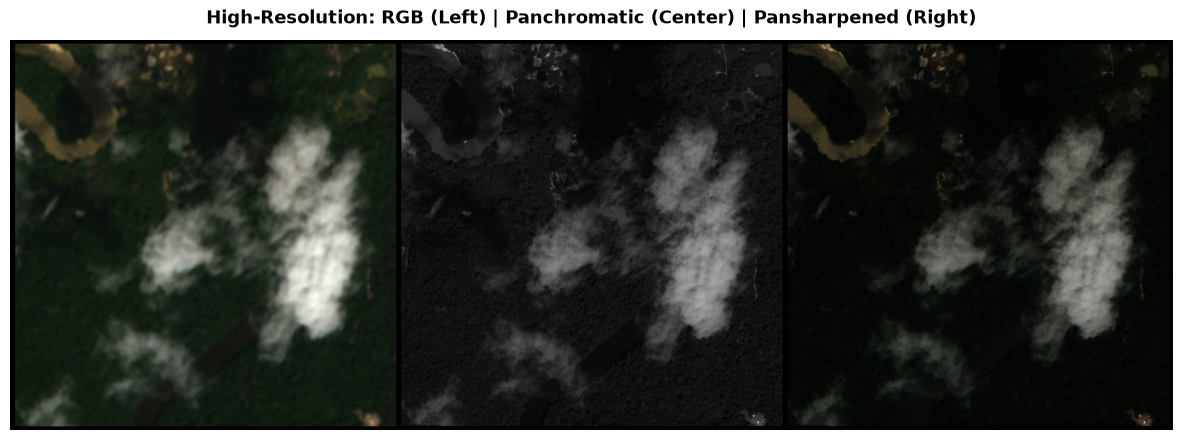

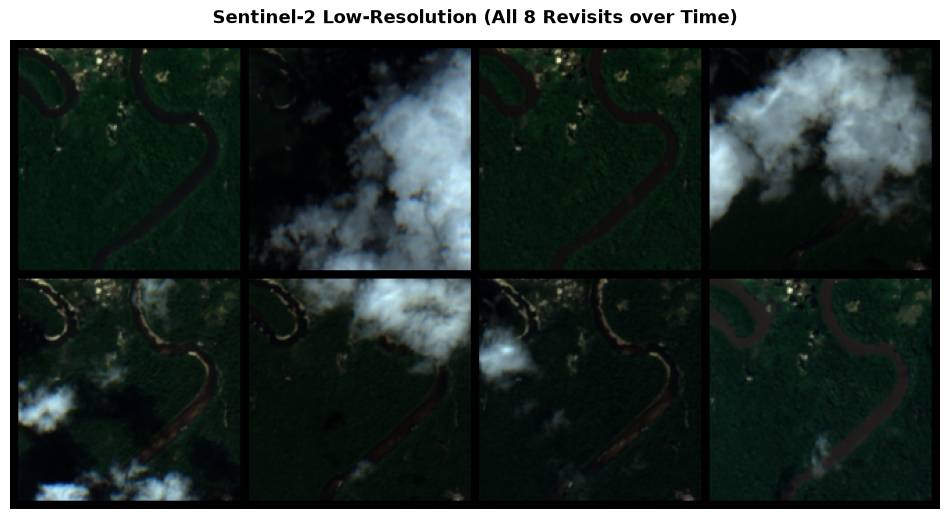

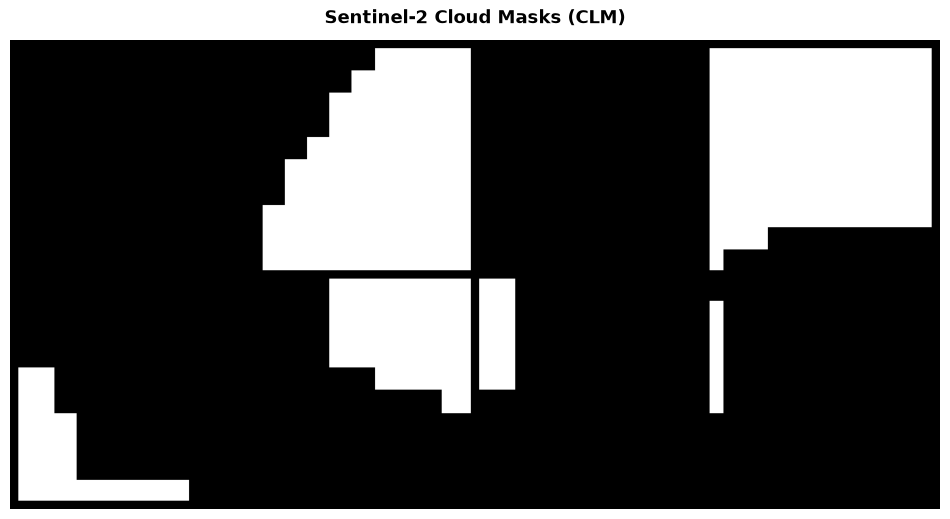

In [38]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

def show_grid(tensor_grid, figsize=12, title=None):
    """Renders a 3D (C, H, W) stitched grid tensor using Matplotlib."""
    img = tensor_grid.permute(1, 2, 0).detach().cpu().numpy()
    plt.figure(figsize=(figsize, figsize))
    if title:
        plt.title(title, fontsize=13, pad=12, fontweight="bold")
    plt.imshow(img)
    plt.axis('off')
    plt.show()

def plot_aoi(dataset, i=18):
    item = dataset[i]
    lr, lrc = item['lr'], item['lrc']
    hr, hr_pan, ps = item['hr'], item['hr_pan'], item['hr_pansharpened']

    print(f"=== AOI Index: {i} | LR Shape: {tuple(lr.shape)} | HR Shape: {tuple(hr.shape)} ===")

    # -------------------------------------------------------------
    # 1. High-Resolution Trio (RGB, Panchromatic, Pansharpened)
    # -------------------------------------------------------------
    rgb = hr[0] if hr.ndim == 4 else hr
    pan = hr_pan[0] if hr_pan.ndim == 4 else hr_pan
    pan_3ch = pan.repeat(3, 1, 1) if pan.shape[0] == 1 else pan[:3]
    ps_img = ps[0] if ps.ndim == 4 else ps

    # Stitch into a 1x3 row
    hr_grid = make_grid([rgb[:3], pan_3ch[:3], ps_img[:3]], nrow=3, normalize=True, scale_each=True, padding=10)
    show_grid(hr_grid, figsize=15, title=f"High-Resolution: RGB (Left) | Panchromatic (Center) | Pansharpened (Right)")

    # -------------------------------------------------------------
    # 2. All 8 Low-Resolution Revisits (2 rows x 4 cols)
    # -------------------------------------------------------------
    # nrow=4 stitches 8 images into 2 rows of 4!
    lr_grid = make_grid(lr[:, :3], nrow=4, normalize=True, scale_each=True, padding=6)
    show_grid(lr_grid, figsize=12, title=f"Sentinel-2 Low-Resolution (All 8 Revisits over Time)")

    # -------------------------------------------------------------
    # 3. All 8 Cloud Masks (2 rows x 4 cols)
    # -------------------------------------------------------------
    lrc_grid = make_grid(lrc, nrow=4, normalize=True, scale_each=True, padding=6)
    show_grid(lrc_grid, figsize=12, title=f"Sentinel-2 Cloud Masks (CLM)")


plot_aoi(dataset, i=18)


In [39]:
import folium
import rasterio
import numpy as np
import ast
import os
import webbrowser
from glob import glob

def show_aoi_map(i=0):
    """
    Renders an interactive satellite map for any index `i` (0 to 3927) showing:
    - Global Live Earth & Street Map Basemaps
    - 1. Low-Res Sentinel-2 (Input - Bands 4, 3, 2)
    - 2. High-Res SPOT (Target - Bands 1, 2, 3)
    - Red AOI Bounding Box
    """
    # -------------------------------------------------------------
    # 1. Coordinates from dataframe
    # -------------------------------------------------------------
    row = df.iloc[i]
    aoi_name = row['index']
    
    bounds = ast.literal_eval(row['bounds']) if isinstance(row['bounds'], str) else row['bounds']
    min_lon, min_lat, max_lon, max_lat = bounds
    center_lat = (min_lat + max_lat) / 2.0
    center_lon = (min_lon + max_lon) / 2.0
    
    print(f"🌍 Rendering AOI #{i}: {aoi_name} at GPS ({center_lat:.4f}, {center_lon:.4f})")

    # -------------------------------------------------------------
    # 2. Base Map: Esri Satellite
    # -------------------------------------------------------------
    m = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=14, 
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Esri World Imagery"
    )

    # Free Street Map layer
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Esri World Street Map",
        name="Clean Street Map (Free)"
    ).add_to(m)

    # -------------------------------------------------------------
    # 3. Locate and Overlay Low-Res Sentinel-2 (Bands 4, 3, 2)
    # -------------------------------------------------------------
    lr_candidates = glob(f"**/lr_dataset/**/{aoi_name}/**/*-L2A_data.tiff", recursive=True)
    if not lr_candidates:
        lr_candidates = glob(f"**/lr_dataset/**/{aoi_name}/*-L2A_data.tiff", recursive=True)
        
    if lr_candidates:
        lr_path = lr_candidates[0]
        print(f"✅ Found Low-Res image:  {lr_path}")
        with rasterio.open(lr_path) as src:
            # Sentinel-2 true-color bands are 4, 3, 2!
            lr_img = src.read((4, 3, 2)).astype(np.float32)
            
        p2, p98 = np.percentile(lr_img, (2, 98))
        lr_img = np.clip((lr_img - p2) / (p98 - p2 + 1e-6) * 255.0, 0, 255).astype(np.uint8).transpose(1, 2, 0)
        
        folium.raster_layers.ImageOverlay(
            image=lr_img,
            bounds=[[min_lat, min_lon], [max_lat, max_lon]],
            opacity=0.9,
            name="1. Low-Res Sentinel-2 (Input)",
            show=False  # Unchecked by default so you can toggle it on
        ).add_to(m)
    else:
        print(f"⚠️ Could not find LR file for {aoi_name}")

    # -------------------------------------------------------------
    # 4. Locate and Overlay High-Res SPOT Image (Bands 1, 2, 3)
    # -------------------------------------------------------------
    hr_candidates = glob(f"**/hr_dataset/**/{aoi_name}/*_ps.tiff", recursive=True)
    if not hr_candidates:
        hr_candidates = glob(f"**/hr_dataset/**/{aoi_name}/*_rgbn.tiff", recursive=True)

    if hr_candidates:
        hr_path = hr_candidates[0]
        print(f"✅ Found High-Res image: {hr_path}")
        with rasterio.open(hr_path) as src:
            # SPOT true-color bands are 1, 2, 3!
            hr_img = src.read((1, 2, 3)).astype(np.float32)
            
        p2, p98 = np.percentile(hr_img, (2, 98))
        hr_img = np.clip((hr_img - p2) / (p98 - p2 + 1e-6) * 255.0, 0, 255).astype(np.uint8).transpose(1, 2, 0)
        
        folium.raster_layers.ImageOverlay(
            image=hr_img,
            bounds=[[min_lat, min_lon], [max_lat, max_lon]],
            opacity=0.9,
            name="2. High-Res SPOT (Target)",
            show=True   # Checked by default
        ).add_to(m)
    else:
        print(f"⚠️ Could not find HR file for {aoi_name}")

    # -------------------------------------------------------------
    # 5. Red Boundary Box & Layer Control Box
    # -------------------------------------------------------------
    folium.Rectangle(
        bounds=[[min_lat, min_lon], [max_lat, max_lon]],
        color="red", weight=3, fill=False, name="AOI Boundary"
    ).add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)

    # Save and pop open in your browser
    m.save("map.html")
    webbrowser.open("map.html")


In [40]:
show_aoi_map(14)

🌍 Rendering AOI #14: Amnesty POI-17-2-3 at GPS (30.2119, -91.0146)
✅ Found Low-Res image:  archive_1/lr_dataset/Amnesty POI-17-2-3/L2A/Amnesty POI-17-2-3-7-L2A_data.tiff
✅ Found High-Res image: archive_1/hr_dataset/12bit/Amnesty POI-17-2-3/Amnesty POI-17-2-3_ps.tiff


/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.


# Training a super-resolution model

The dataset comes with several pretrained super-resolution models we used as a benchmark:

- HighResNet
- SRCNN Multi-Frame
- SRCNN Single-Image

In [41]:
%load_ext autoreload
%autoreload 2
import sys

Phase-1


Input: All 12 Sentinel-2 bands (in_channels = 12)—the model uses visual RGB, Near-Infrared (NIR), Short-Wave Infrared (SWIR), and Red-Edge bands as input cues.
Output: 3-channel True Color RGB (out_channels = 3).

In [42]:
"""
crucial step for DataLoader (If using multi-processing):

If your data loading pipeline utilizes multi-processing (num_workers > 0), the workers will duplicate the random state of the parent process,
 causing them to return identical batches. 
You must pass a worker_init_fn and a torch.Generator directly to the DataLoader to avoid this:"""
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(42)


In [43]:
#inspecting the datset before training model
import torch
from torch.utils.data import DataLoader

train_loader  = DataLoader(
    dataset,
    batch_size=10,
    shuffle=True,
    num_workers=0,#making it greawteher than 0 giving error as i have to updatin tranformation lambda funciton as per new python
    worker_init_fn=seed_worker,
    generator=g
)
#batch 2 mean 2 aois with 8 revisits
# Pull 1 test batch
batch = next(iter(train_loader))

print("=== BATCH TENSOR SHAPES & VALUE RANGES ===")
print("LR (S2 Input):           ", batch['lr'].shape,              "| Min/Max:", batch['lr'].min().item(), batch['lr'].max().item())
print("LRC (Cloud Mask):        ", batch['lrc'].shape,             "| Min/Max:", batch['lrc'].min().item(), batch['lrc'].max().item())
print("HR Pansharpened (Target):", batch['hr_pansharpened'].shape, "| Min/Max:", batch['hr_pansharpened'].min().item(), batch['hr_pansharpened'].max().item())


/mnt/storage/OneDrive_4_14-04-2025/Super_resolution/.venv/lib/python3.14/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
Created TensorFlow Lite XNNPACK delegate for CPU.


=== BATCH TENSOR SHAPES & VALUE RANGES ===
LR (S2 Input):            torch.Size([10, 8, 3, 160, 160]) | Min/Max: -0.4761601984500885 14.656059265136719
LRC (Cloud Mask):         torch.Size([10, 8, 1, 160, 160]) | Min/Max: 0.0 1.0
HR Pansharpened (Target): torch.Size([10, 1, 3, 1054, 1054]) | Min/Max: 0.0 1.0


In [44]:
train_loader

In [45]:
for batch in train_loader:
    # 1. Run your diagnostic prints on the first batch
    print("LR Shape: ", batch['lr'].shape)
    print("LR Range: ", batch['lr'].min().item(), "to", batch['lr'].max().item())
    break


LR Shape:  torch.Size([10, 8, 3, 160, 160])
LR Range:  -0.8540739417076111 to 14.511876106262207


In [46]:
for i, batch in enumerate(train_loader):
    print(f"Batch {i} - LR Shape: {batch['lr'].shape} | Target Shape: {batch['hr_pansharpened'].shape}")
    
    # Stop after 3 batches (0, 1, 2)
    if i >= 2:
        break

[76629:76669:1104/142441.982991:ERROR:google_apis/gcm/engine/registration_request.cc:291] Registration response error message: DEPRECATED_ENDPOINT


Batch 0 - LR Shape: torch.Size([10, 8, 3, 160, 160]) | Target Shape: torch.Size([10, 1, 3, 1054, 1054])
Batch 1 - LR Shape: torch.Size([10, 8, 3, 160, 160]) | Target Shape: torch.Size([10, 1, 3, 1054, 1054])
Batch 2 - LR Shape: torch.Size([10, 8, 3, 160, 160]) | Target Shape: torch.Size([10, 1, 3, 1054, 1054])


In [47]:
print("LR Batch Mean:", batch['lr'].mean().item())
print("LR Batch Std: ", batch['lr'].std().item())


LR Batch Mean: 1.8883252143859863
LR Batch Std:  2.76896071434021


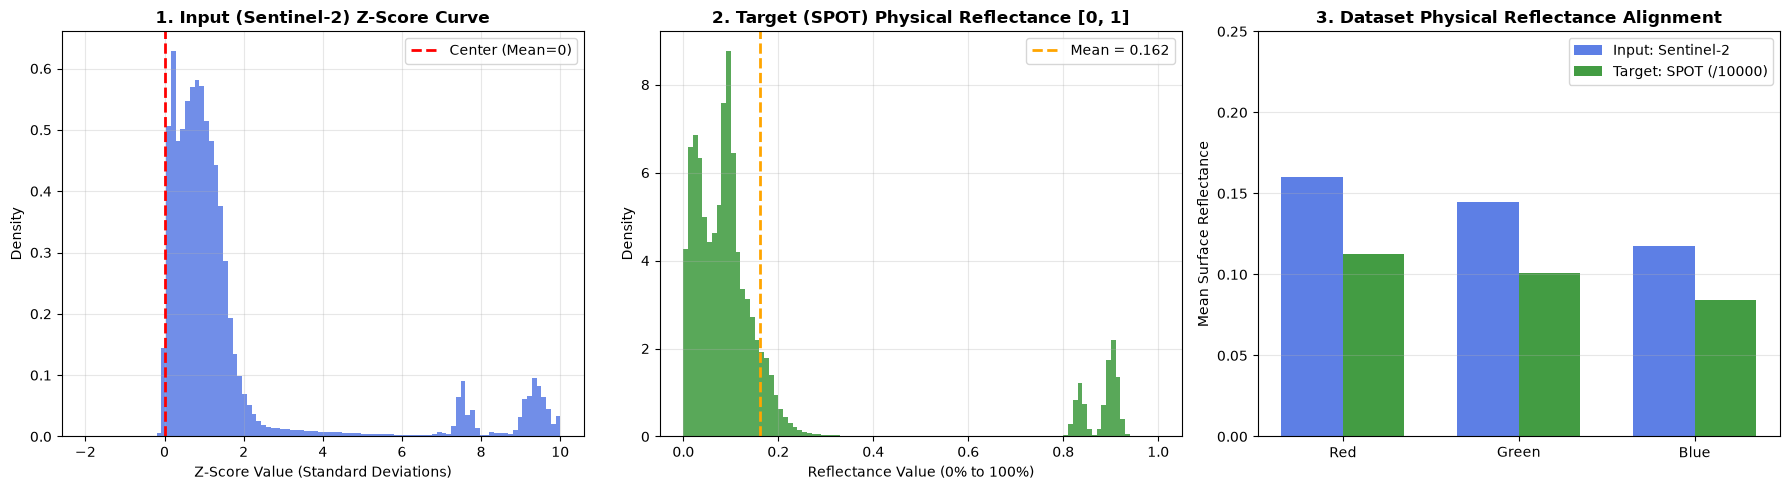

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

# =========================================================================
# 1. DISTRIBUTION CURVES (Histograms & Density)
# =========================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (A) Low-Res Input Distribution (Z-score standardized)
lr_pixels = batch['lr'].flatten().numpy()
axes[0].hist(lr_pixels, bins=100, color='royalblue', alpha=0.75, density=True, range=(-2, 10))
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='Center (Mean=0)')
axes[0].set_title("1. Input (Sentinel-2) Z-Score Curve", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Z-Score Value (Standard Deviations)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# (B) High-Res Target Distribution (Normalized [0.0, 1.0])
hr_pixels = batch['hr_pansharpened'].flatten().numpy()
axes[1].hist(hr_pixels, bins=100, color='forestgreen', alpha=0.75, density=True, range=(0, 1))
axes[1].axvline(hr_pixels.mean(), color='orange', linestyle='--', linewidth=2, label=f'Mean = {hr_pixels.mean():.3f}')
axes[1].set_title("2. Target (SPOT) Physical Reflectance [0, 1]", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Reflectance Value (0% to 100%)")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# =========================================================================
# 2. CROSS-SENSOR REFLECTANCE ALIGNMENT (Bar Chart)
# =========================================================================
# We compare the average reflectance across all 35,000 images from compute_dataset_stats.py
channels = ['Red', 'Green', 'Blue']
s2_means = [0.1600, 0.1445, 0.1175]           # Sentinel-2 raw reflectance
spot_means = [1128.4/10000, 1011.2/10000, 845.1/10000] # SPOT normalized (/10000)

x = np.arange(len(channels))
width = 0.35

axes[2].bar(x - width/2, s2_means, width, label='Input: Sentinel-2', color='royalblue', alpha=0.85)
axes[2].bar(x + width/2, spot_means, width, label='Target: SPOT (/10000)', color='forestgreen', alpha=0.85)
axes[2].set_title("3. Dataset Physical Reflectance Alignment", fontsize=12, fontweight='bold')
axes[2].set_xticks(x)
axes[2].set_xticklabels(channels)
axes[2].set_ylabel("Mean Surface Reflectance")
axes[2].set_ylim(0, 0.25)
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


cli_main()

In [49]:
#function definition in this cell

import wandb #uses cloud storgae for git like exepriments checkpoints and code savepoints

def initialise_wandb(args=None):
    """Initialises WandB for experiment tracking."""
    
    # 1. Safely check for upload_checkpoint attribute without crashing if missing
    upload_cp = getattr(args, "upload_checkpoint", False) if args else False
    tags = ["inference"] if upload_cp else ["training"]
    
    # 2. Extract hyperparameters dictionary to log in WandB dashboard
    config_dict = vars(args) if hasattr(args, "__dict__") else (args if isinstance(args, dict) else {})
    
    # 3. Initialize WandB Run with project, tags, and config
    run = wandb.init(
        project="worldstrat-super-res",
        tags=tags,
        config=config_dict
    )
    
    # 4. Only snapshot code files (.ipynb and .py), avoiding large TIFF/checkpoint files!
    wandb.run.log_code(
        ".", 
        include_fn=lambda path: path.endswith(".py") or path.endswith(".ipynb")
    )
    
    return run
def finish_wandb_logging(args):
    """ Finishes logging in WandB.
    Uploads the model to WandB if the upload_checkpoint flag is set.

    Parameters
    ----------
    args : argparse.Namespace
        Parsed arguments containing the random seed (args.seed).
    """
    if args.upload_checkpoint:
        wandb.save(f"checkpoints/{wandb.run.id}-checkpoint.ckpt")
    wandb.finish()


def load_dataset(args):
    """ Loads the appropriate dataset into dataloaders 
    based on the passed dataset argument.

    Parameters
    ----------
    args : argparse.Namespace
        Arguments parsed from the CLI and model and project specific arguments.

    Returns
    -------
    dict
        Dictionary containing the dataloaders for the training, validation and
        test set.

    Raises
    ------
    Exception
        If the passed dataset name doesn't exist.
    Exception
        If the dataset root is missing.
    """
    if args.dataset == "JIF":
        dataloaders = load_dataset_JIF(**vars(args))
    elif args.dataset == "SN7":
        dataloaders = load_dataset_SN7(**vars(args))
    elif args.dataset == "PROBAV":
        dataloaders = load_dataset_ProbaV(**vars(args))
    else:
        raise Exception("Undefined dataset. Can't create dataloaders.")

    if args.root is None:
        raise Exception("The root path of the dataset needs to be set.")
    return dataloaders




def generate_model_backbone(args, dataloaders):
    """ Generates the model backbone from the arguments and the dataset.

    Parameters
    ----------
    args : argparse.Namespace
        Arguments parsed from the CLI and model and project specific arguments.
    dataloaders : dict
        Dictionary containing the dataloaders for the training, validation and
    """
    in_channels = dataloaders["train"].dataset[0]["lr"].shape[1]
    out_channels = dataloaders["train"].dataset[0]["hr"].shape[1]
    mask_channels = dataloaders["train"].dataset[0]["lrc"].shape[1]
    if args.use_masks:
        in_channels += mask_channels
    crop_ratio = args.chip_size[0] / args.input_size[0]
    output_height, output_width = args.output_size
    cropped_output_size = (
        round(output_height * crop_ratio),
        round(output_width * crop_ratio),
    )

    # TODO: pass hparams as kwargs
    model_cls = eval(args.model)  # Backbone
    vars(args)["backbone"] = model_cls(
        in_channels=in_channels,
        mask_channels=mask_channels,
        revisits=args.revisits,
        hidden_channels=args.hidden_channels,
        homography_fc_size=args.homography_fc_size,
        out_channels=out_channels,
        kernel_size=args.kernel_size,
        residual_layers=args.residual_layers,
        output_size=cropped_output_size,
        zoom_factor=args.zoom_factor,
        sr_kernel_size=args.sr_kernel_size,
        skip_paddings=True,
        registration_kind=args.registration_kind,
        use_reference_frame=args.use_reference_frame,
    )



In [50]:

#i will not be using wandb hre as not made an account
#random seeed set at start
#dataloaders = load_dataset("args")

AttributeError: 'str' object has no attribute 'dataset'

In [55]:
import torch
import random
import numpy as np
from torch.utils.data import DataLoader, random_split

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def load_dataset(dataset, batch_size=2, train_pct=0.80, val_pct=0.10, seed=42):
    """
    Splits the DictDataset and returns 3 independent DataLoaders.
    """
    total_len = len(dataset)
    train_len = int(train_pct * total_len)
    val_len   = int(val_pct * total_len)
    test_len  = total_len - train_len - val_len

    # Deterministic split
    split_gen = torch.Generator().manual_seed(seed)
    train_set, val_set, test_set = random_split(
        dataset, [train_len, val_len, test_len], generator=split_gen
    )

    # Shuffling generator for training batches
    loader_gen = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_set, batch_size=batch_size, shuffle=True,
        num_workers=0, worker_init_fn=seed_worker, generator=loader_gen
    )
    val_loader = DataLoader(
        val_set, batch_size=batch_size, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        test_set, batch_size=batch_size, shuffle=False, num_workers=0
    )

    print(f"✓ Ready: Train={len(train_set)} | Val={len(val_set)} | Test={len(test_set)} scenes")
    return train_loader, val_loader, test_loader

In [59]:
train_loader, val_loader, test_loader = load_dataset(dataset, batch_size=2)

# Sanity check
sample_batch = next(iter(train_loader))

print("✓ Train LR Shape: ", sample_batch["lr"].shape)
print("✓ Train LRC Shape: ", sample_batch["lrc"].shape)
print("✓ Train HR Shape: ", sample_batch["hr_pansharpened"].shape)

✓ Ready: Train=3142 | Val=392 | Test=394 scenes
✓ Train LR Shape:  torch.Size([2, 8, 3, 160, 160])
✓ Train LRC Shape:  torch.Size([2, 8, 1, 160, 160])
✓ Train HR Shape:  torch.Size([2, 1, 3, 1054, 1054])


In [75]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
import numpy as np

class BicubicUpscaledBaseline(nn.Module):
    """ Bicubic upscaled single-image baseline. """

    def __init__(
        self, input_size=(160, 160), output_size=(1054, 1054), chip_size=(160, 160), interpolation="bicubic", device=None, **kws
    ):
        """ Initialize the BicubicUpscaledBaseline.

        Parameters
        ----------
        input_size : tuple of int
            The input size (Height, Width).
        output_size : tuple of int
            The output size (Height, Width).
        chip_size : tuple of int
            The chip size.
        interpolation : str, optional
            The interpolation method, by default 'bicubic'.
            Available methods: 'nearest', 'bilinear', 'bicubic'.
        device : torch.device, optional
            Device on which to perform computation (CPU or CUDA).
        """
        super().__init__()
        assert interpolation in ["bilinear", "bicubic", "nearest"]
        self.interpolation = interpolation
        self.output_size = output_size
        self.input_size = input_size
        self.chip_size = chip_size
        
        # S2 RGB bands (Bands 4, 3, 2 mapped to 0-indexed [3, 2, 1])
        self.lr_bands = np.array(S2_ALL_12BANDS["true_color"]) - 1
        self.mean = JIF_S2_MEAN[self.lr_bands]
        self.std = JIF_S2_STD[self.lr_bands]
        self.device = device

    def forward(self, x: Tensor) -> Tensor:
        """ Forward pass of the BicubicUpscaledBaseline.

        Parameters
        ----------
        x : Tensor
            The input tensor (a batch of multi-temporal low-res revisits).
            Shape: (batch_size, revisits, channels, height, width).

        Returns
        -------
        Tensor
            The output tensor (a single upscaled low-res revisit).
            Shape: (batch_size, 1, channels, output_height, output_width).
        """

        # 1. If 12 bands, select the 3 RGB bands
        if x.shape[2] > 3:
            x = x[:, :, S2_ALL_12BANDS["true_color_zero_index"]]

        # 2. Select Revisit 0 -> Stays in natural 4D: (Batch, Channels, Height, Width)
        x = x[:, 0, :, :, :]

        # 3. Setup 4D Mean & Std using None (Shape: 1, 3, 1, 1)
        device = x.device if self.device is None else self.device
        std_4d = torch.as_tensor(self.std, dtype=torch.float32, device=device)[None, :, None, None]
        mean_4d = torch.as_tensor(self.mean, dtype=torch.float32, device=device)[None, :, None, None]

        # 4. De-normalize & Clamp directly in 4D
        x *= std_4d
        x += mean_4d
        x = x.clamp(min=0.0, max=1.0)

        # 5. Clean 2D Interpolation (No .view() needed at all!)
        x = F.interpolate(x, size=self.output_size, mode=self.interpolation, align_corners=False)
        x = x.clamp(min=0.0, max=1.0)

        # 6. Add dummy revisit dimension using None to match SPOT target (B, 1, 3, H, W)
        return x[:, None, :, :, :]

In [76]:
# Just testing each stage of bicubic upscaling baseline model
import torch
import torch.nn.functional as F
import numpy as np

# 1. Grab your sample tensor
x = sample_batch['lr'].clone()
print("=================================================================")
print("STEP 0 (Input Tensor):")
print("  Shape:", x.shape)
print("  Range:", f"{x.min().item():.4f} to {x.max().item():.4f} (Z-Score domain)")
print("=================================================================")

# STEP 1: Select first revisit (explicit 5D indexing)
x = x[:, 0, :, :, :]
print("\nSTEP 1 (Select Revisit 0):")
print("  Shape:", x.shape, " <-- Temporal dimension collapsed to 4D")

# STEP 2: Re-add dummy revisit dimension using None
x = x[:, None, :, :, :]
print("\nSTEP 2 (Pad Revisit Dim with None):")
print("  Shape:", x.shape, " <-- Reshaped to 5D: (Batch, 1, Channels, H, W)")

# STEP 3: Setup Mean and Std as PyTorch Tensors FIRST for RGB bands
lr_bands = np.array(S2_ALL_12BANDS["true_color"]) - 1
device = x.device

# Convert NumPy arrays to PyTorch Tensors on the correct device first:
std_tensor = torch.as_tensor(JIF_S2_STD[lr_bands], dtype=torch.float32, device=device)
mean_tensor = torch.as_tensor(JIF_S2_MEAN[lr_bands], dtype=torch.float32, device=device)

# Expand dimensions to 5D using None: shape becomes (1, 1, 3, 1, 1)
std_5d = std_tensor[None, None, :, None, None]
mean_5d = mean_tensor[None, None, :, None, None]

# STEP 4: De-normalize: Multiply by std first, then add mean (x * std + mean)
x *= std_5d
x += mean_5d
print("\nSTEP 4 (De-Normalized):")
print("  Range:", f"{x.min().item():.4f} to {x.max().item():.4f} (Back in Physical Reflectance!)")

# STEP 5: Clamp strictly to [0.0, 1.0] (remove negative shadows and specular glare)
x = x.float().clamp(min=0.0, max=1.0)
print("\nSTEP 5 (Clamped [0, 1]):")
print("  Range:", f"{x.min().item():.4f} to {x.max().item():.4f}")

# STEP 6: Upscale to 1054x1054 using Bicubic Interpolation
output_size = (1054, 1054)

# Squeeze revisit dim to 4D for interpolation: (B, C, H, W)
x_4d = x[:, 0, :, :, :]
x_up = F.interpolate(x_4d, size=output_size, mode="bicubic", align_corners=False)

# Re-pad revisit dimension to 5D using None: (B, 1, C, H_out, W_out)
x_upscaled = x_up[:, None, :, :, :].clamp(min=0.0, max=1.0)

print("\nSTEP 6 (Bicubic Upscaled Output):")
print("  Shape:", x_upscaled.shape, " <-- Exactly matches SPOT ground truth!")
print("  Range:", f"{x_upscaled.min().item():.4f} to {x_upscaled.max().item():.4f}")
print("=================================================================")

STEP 0 (Input Tensor):
  Shape: torch.Size([2, 8, 3, 160, 160])
  Range: -0.1433 to 17.3591 (Z-Score domain)

STEP 1 (Select Revisit 0):
  Shape: torch.Size([2, 3, 160, 160])  <-- Temporal dimension collapsed to 4D

STEP 2 (Pad Revisit Dim with None):
  Shape: torch.Size([2, 1, 3, 160, 160])  <-- Reshaped to 5D: (Batch, 1, Channels, H, W)

STEP 4 (De-Normalized):
  Range: 0.0148 to 0.2457 (Back in Physical Reflectance!)

STEP 5 (Clamped [0, 1]):
  Range: 0.0148 to 0.2457

STEP 6 (Bicubic Upscaled Output):
  Shape: torch.Size([2, 1, 3, 1054, 1054])  <-- Exactly matches SPOT ground truth!
  Range: 0.0132 to 0.2521


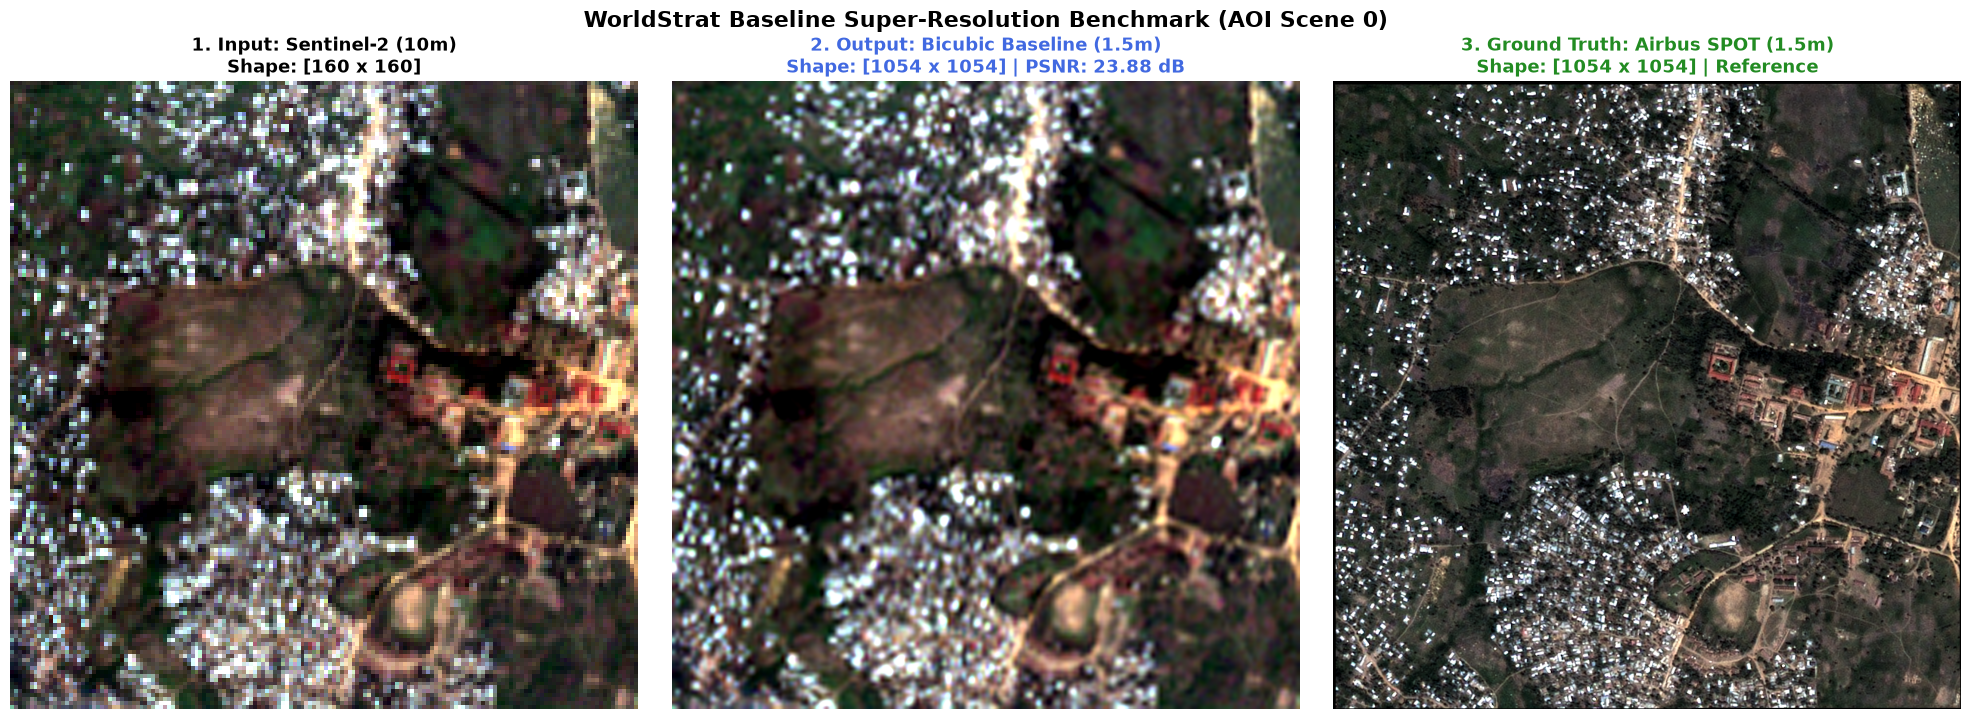

In [80]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import numpy as np

# =========================================================================
# 1. RUN INFERENCE & GET TENSORS
# =========================================================================
baseline = BicubicUpscaledBaseline(output_size=(1054, 1054))
with torch.no_grad():
    y_baseline = baseline(sample_batch['lr'])

batch_idx = 0

# (A) INPUT: S2 Revisit 0 (De-normalized to physical reflectance)
lr_bands = np.array(S2_ALL_12BANDS["true_color"]) - 1
device = sample_batch['lr'].device
std_4d = torch.as_tensor(JIF_S2_STD[lr_bands], dtype=torch.float32, device=device)[None, :, None, None]
mean_4d = torch.as_tensor(JIF_S2_MEAN[lr_bands], dtype=torch.float32, device=device)[None, :, None, None]

lr_input = sample_batch['lr'][batch_idx, 0, :, :, :].unsqueeze(0)
lr_denorm = (lr_input * std_4d + mean_4d).clamp(0, 1).squeeze(0)  # Shape: (3, 160, 160)

# (B) OUTPUT: Bicubic Upscaled (3, 1054, 1054)
output_img = y_baseline[batch_idx, 0, :, :, :]

# (C) GROUND TRUTH: Airbus SPOT Target (3, 1054, 1054)
ground_truth = sample_batch['hr_pansharpened'][batch_idx, 0, :, :, :]

# =========================================================================
# 2. QUANTITATIVE BENCHMARK (Evaluated on physical reflectance)
# =========================================================================
mse = F.mse_loss(output_img, ground_truth)
psnr = 10 * torch.log10(1.0 / mse)

# =========================================================================
# 3. 2%–98% DAYLIGHT CONTRAST STRETCH (Per-channel, ignores roof glints)
# =========================================================================
def stretch_to_daylight(img_tensor):
    """Clips 2% outliers so high-res specular glints do not darken the scene into night."""
    arr = img_tensor.detach().cpu().numpy()  # (C, H, W)
    out = np.zeros_like(arr)
    for c in range(arr.shape[0]):
        p2 = np.percentile(arr[c], 2)
        p98 = np.percentile(arr[c], 98)
        if p98 > p2:
            out[c] = np.clip((arr[c] - p2) / (p98 - p2), 0.0, 1.0)
        else:
            out[c] = np.clip(arr[c], 0.0, 1.0)
    # Permute (C, H, W) -> (H, W, C) for Matplotlib
    return np.transpose(out, (1, 2, 0))

disp_input  = stretch_to_daylight(lr_denorm)
disp_output = stretch_to_daylight(output_img)
disp_target = stretch_to_daylight(ground_truth)

# =========================================================================
# 4. PLOT SIDE-BY-SIDE IN FULL DAYLIGHT
# =========================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Input: Sentinel-2
axes[0].imshow(disp_input)
axes[0].set_title("1. Input: Sentinel-2 (10m)\nShape: [160 x 160]", fontsize=13, fontweight='bold')
axes[0].axis('off')

# 2. Output: Bicubic Baseline
axes[1].imshow(disp_output)
axes[1].set_title(f"2. Output: Bicubic Baseline (1.5m)\nShape: [1054 x 1054] | PSNR: {psnr.item():.2f} dB", fontsize=13, fontweight='bold', color='royalblue')
axes[1].axis('off')

# 3. Ground Truth: Airbus SPOT
axes[2].imshow(disp_target)
axes[2].set_title("3. Ground Truth: Airbus SPOT (1.5m)\nShape: [1054 x 1054] | Reference", fontsize=13, fontweight='bold', color='forestgreen')
axes[2].axis('off')

plt.suptitle(f"WorldStrat Baseline Super-Resolution Benchmark (AOI Scene {batch_idx})", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()